In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from datasist.structdata import detect_outliers

pio.renderers.default = "png"

data_path = r'datasets/Titanic.csv'  

# - Titanic handling outliers values

In [3]:
df = pd.read_csv(data_path)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


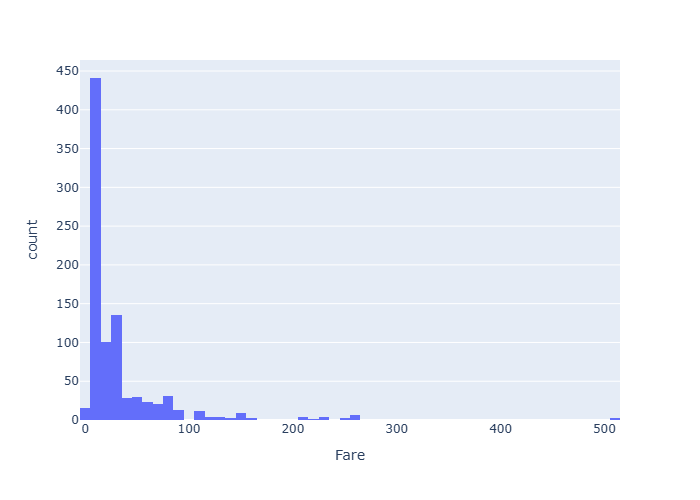

In [4]:
# Col `Fare` ~~>> Check outliers

px.histogram(df, x= 'Fare')

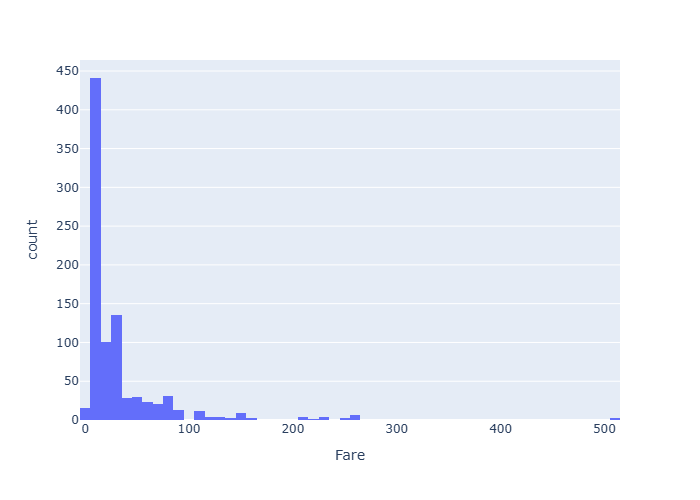

In [5]:
# To drop outliers

outlier_indices = detect_outliers(data= df, n= 0, features= ['Fare'])
df.drop(outlier_indices, axis= 0).reset_index()
px.histogram(df, x= 'Fare')

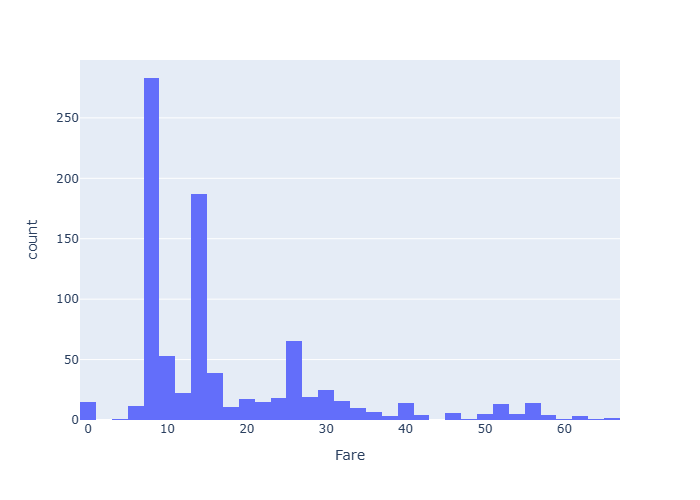

In [6]:
# To replace outliers with median

outlier_indices = detect_outliers(data= df, n= 0, features= ['Fare'])
df.loc[outlier_indices, 'Fare'] = df['Fare'].median()
px.histogram(df, x= 'Fare')

- Create Custom function to detect outliers based on Percentile


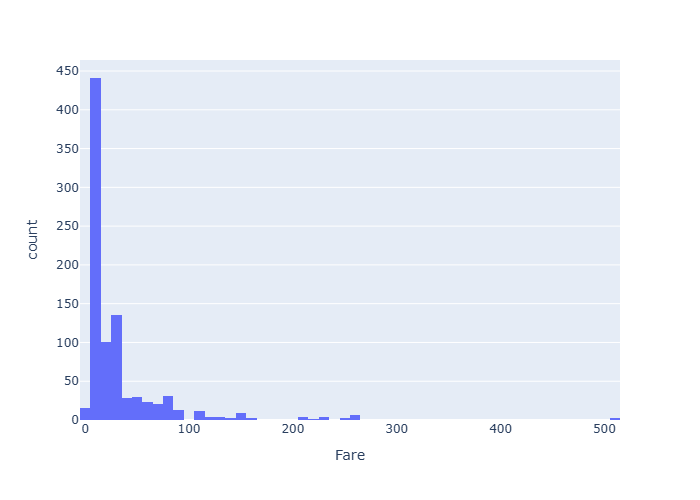

In [7]:
# Create Custom function to detect outliers based on Percentile

df = pd.read_csv(data_path)
px.histogram(df, x= 'Fare')


In [8]:
def custom_outliers(data_frame : pd.DataFrame, col : str, lower_range = 0.1, upper_range = 0.9):
    
    # Get (lower & upper) bound values

    lower_bound = data_frame[col].quantile(lower_range)
    upper_bound = data_frame[col].quantile(upper_range)

    outlier_index = data_frame[(data_frame[col] < lower_bound) | (data_frame[col] > upper_bound)].index.tolist()
    return outlier_index

In [9]:
custom_outliers(df, 'Fare')

[0,
 19,
 26,
 27,
 31,
 34,
 36,
 57,
 60,
 61,
 62,
 88,
 94,
 118,
 127,
 129,
 131,
 139,
 143,
 154,
 179,
 195,
 202,
 203,
 210,
 212,
 215,
 224,
 227,
 230,
 243,
 244,
 245,
 250,
 256,
 257,
 258,
 262,
 263,
 268,
 269,
 271,
 277,
 290,
 291,
 296,
 297,
 299,
 302,
 305,
 306,
 307,
 310,
 311,
 318,
 319,
 320,
 325,
 326,
 332,
 334,
 337,
 341,
 352,
 354,
 363,
 365,
 367,
 371,
 373,
 375,
 376,
 377,
 378,
 380,
 390,
 393,
 411,
 412,
 413,
 425,
 433,
 435,
 438,
 445,
 453,
 465,
 466,
 470,
 477,
 478,
 481,
 484,
 486,
 491,
 496,
 498,
 504,
 505,
 514,
 520,
 522,
 524,
 527,
 531,
 532,
 537,
 544,
 550,
 553,
 557,
 558,
 568,
 581,
 585,
 587,
 590,
 591,
 592,
 597,
 598,
 609,
 611,
 631,
 633,
 654,
 659,
 660,
 661,
 663,
 674,
 679,
 689,
 693,
 698,
 700,
 708,
 716,
 721,
 730,
 732,
 737,
 741,
 742,
 759,
 761,
 762,
 763,
 773,
 779,
 780,
 784,
 785,
 786,
 789,
 798,
 802,
 804,
 806,
 815,
 818,
 820,
 822,
 825,
 829,
 832,
 835,
 843,
 849,


In [10]:
len(custom_outliers(df, 'Fare'))

175

In [11]:
# Check outliers from range (0.1 : 0.99)

custom_outliers(df, 'Fare', lower_range= 0.1, upper_range= 0.99)

[0,
 19,
 26,
 27,
 36,
 57,
 60,
 88,
 94,
 127,
 129,
 131,
 143,
 154,
 179,
 202,
 203,
 210,
 212,
 227,
 243,
 244,
 250,
 258,
 263,
 271,
 277,
 296,
 302,
 311,
 320,
 326,
 341,
 352,
 354,
 363,
 365,
 367,
 371,
 376,
 378,
 411,
 413,
 425,
 433,
 438,
 465,
 466,
 470,
 477,
 478,
 481,
 491,
 514,
 522,
 524,
 531,
 532,
 553,
 568,
 590,
 592,
 597,
 598,
 611,
 631,
 633,
 654,
 661,
 663,
 674,
 679,
 693,
 721,
 732,
 737,
 742,
 761,
 762,
 773,
 780,
 784,
 785,
 786,
 798,
 804,
 806,
 815,
 818,
 822,
 825,
 832,
 843,
 859,
 872,
 875,
 884]

In [12]:
len(custom_outliers(df, 'Fare', lower_range= 0.1, upper_range= 0.99))

97